# Обучение и сравнение моделей стоимости недвижимости

В этом ноутбуке показан полный процесс обучения моделей: подготовка выборок,
baseline, три разных алгоритма машинного обучения, расчёт метрик, подбор
гиперпараметров и сохранение итоговой модели.

Основная метрика — **MAE**, так как её можно интерпретировать как среднюю ошибку
в долларах. Дополнительно рассчитываются RMSE и $R^2$. Все преобразования
признаков входят в pipeline и обучаются только на train-выборке.

In [1]:
from pathlib import Path
import sys
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, RandomizedSearchCV

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data import MODEL_FEATURES, load_raw_data, prepare_dataset
from src.train import build_hist_model, build_model, build_random_forest_model

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 120)
print(f"Рабочая папка: {PROJECT_ROOT}")

Рабочая папка: C:\Users\doronin-vl\Documents\repos\SQL 2026\обучение\проект


## 1. Загрузка и подготовка данных

Используется та же функция очистки, что и в EDA. Из выборки исключаются аренда,
земельные участки, дубли и строки с некорректной целевой ценой. Признак
`Price/sqft` не используется из-за утечки целевой переменной.

In [2]:
started = time.perf_counter()
raw = load_raw_data(PROJECT_ROOT / "data.csv.zip")
data, audit = prepare_dataset(raw)
print(f"Подготовка заняла {time.perf_counter() - started:.1f} сек.")
display(pd.DataFrame([audit]).T.rename(columns={0: "значение"}))
print(f"Итоговый размер данных: {data.shape}")

Подготовка заняла 17.2 сек.


,значение
raw_rows,377185
duplicate_rows_removed,242
rental_rows_removed,398
land_rows_removed,31403
invalid_target_rows_removed,3684
prepared_rows,339000
rows_with_missing_sqft,25378
rows_with_missing_beds,79282
rows_with_missing_baths,92141


Итоговый размер данных: (339000, 19)


## 2. Разделение на train и test

Обычное случайное разделение могло бы поместить объявления одного адреса в обе
выборки. Поэтому применяется `GroupShuffleSplit`, где группой является адрес и
почтовый индекс. Test используется только для окончательной оценки.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(
    splitter.split(data, data["target"], groups=data["listing_group"])
)
train_data = data.iloc[train_idx].copy()
test_data = data.iloc[test_idx].copy()

x_train = train_data[MODEL_FEATURES]
y_train = train_data["target"].astype(float)
x_test = test_data[MODEL_FEATURES]
y_test = test_data["target"].astype(float)

group_overlap = set(train_data["listing_group"]) & set(test_data["listing_group"])
print(f"Train: {len(train_data):,} строк")
print(f"Test:  {len(test_data):,} строк")
print(f"Пересечение адресов: {len(group_overlap)}")

Train: 271,442 строк
Test:  67,558 строк
Пересечение адресов: 0


In [4]:
def calculate_metrics(y_true, predictions):
    return {
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": root_mean_squared_error(y_true, predictions),
        "R2": r2_score(y_true, predictions),
    }


def fit_and_evaluate(name, model):
    started = time.perf_counter()
    model.fit(x_train, y_train)
    fit_seconds = time.perf_counter() - started
    predictions = model.predict(x_test)
    row = {"model": name, **calculate_metrics(y_test, predictions), "fit_seconds": fit_seconds}
    print(
        f"{name}: MAE=${row['MAE']:,.0f}, RMSE=${row['RMSE']:,.0f}, "
        f"R²={row['R2']:.3f}, обучение={fit_seconds:.1f} сек."
    )
    return model, predictions, row


results = []

## 3. Baseline

Baseline всегда предсказывает медианную цену обучающей выборки. Более сложные
модели должны заметно превосходить этот результат.

In [5]:
baseline = DummyRegressor(strategy="median")
baseline, baseline_predictions, baseline_result = fit_and_evaluate("Dummy baseline", baseline)
results.append(baseline_result)

Dummy baseline: MAE=$383,788, RMSE=$909,568, R²=-0.079, обучение=0.0 сек.


## 4. Ridge

Ridge — линейная модель с L2-регуляризацией. Числовые признаки масштабируются,
категориальные кодируются One-Hot Encoding, а цена логарифмируется.

In [6]:
ridge_model, ridge_predictions, ridge_result = fit_and_evaluate(
    "Ridge", build_model()
)
results.append(ridge_result)

Ridge: MAE=$212,161, RMSE=$590,570, R²=0.545, обучение=3.4 сек.


## 5. Random Forest

Random Forest представляет бэггинг деревьев решений и может находить
нелинейные зависимости и взаимодействия признаков. Чтобы время обучения
оставалось разумным, глубина деревьев ограничена.

In [7]:
forest_model, forest_predictions, forest_result = fit_and_evaluate(
    "Random Forest", build_random_forest_model()
)
results.append(forest_result)

Random Forest: MAE=$189,894, RMSE=$547,056, R²=0.610, обучение=7.3 сек.


## 6. HistGradientBoosting

Градиентный бустинг последовательно исправляет ошибки предыдущих деревьев.
Этот алгоритм хорошо подходит для большого табличного датасета.

In [8]:
hist_model, hist_predictions, hist_result = fit_and_evaluate(
    "HistGradientBoosting", build_hist_model()
)
results.append(hist_result)

HistGradientBoosting: MAE=$189,397, RMSE=$539,233, R²=0.621, обучение=3.2 сек.


## 7. Первичное сравнение моделей

,model,MAE,RMSE,R2,fit_seconds
0,HistGradientBoosting,"$189,397","$539,233",0.621,3.2
1,Random Forest,"$189,894","$547,056",0.610,7.3
2,Ridge,"$212,161","$590,570",0.545,3.4
3,Dummy baseline,"$383,788","$909,568",-0.079,0.0


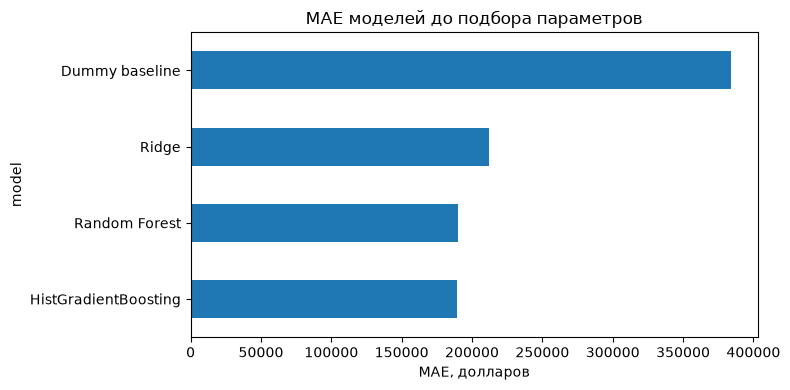

In [9]:
results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
display(results_df.style.format({"MAE": "${:,.0f}", "RMSE": "${:,.0f}", "R2": "{:.3f}", "fit_seconds": "{:.1f}"}))

results_df.set_index("model")["MAE"].sort_values().plot.barh(figsize=(8, 4))
plt.title("MAE моделей до подбора параметров")
plt.xlabel("MAE, долларов")
plt.tight_layout()
plt.show()

## 8. Подбор гиперпараметров

Параметры подбираются только для наиболее подходящего алгоритма —
HistGradientBoosting. Поиск проводится на случайной части train и использует
трёхфолдовую групповую валидацию. Test при подборе не используется.

Проверяются скорость обучения, число итераций, число листьев и L2-регуляризация.
Четырёх случайных комбинаций достаточно для демонстрации процесса без
неоправданно долгого расчёта.

In [10]:
tune_data = train_data.sample(n=min(60_000, len(train_data)), random_state=RANDOM_STATE)
x_tune = tune_data[MODEL_FEATURES]
y_tune = tune_data["target"].astype(float)
groups_tune = tune_data["listing_group"]

parameter_distributions = {
    "estimator__regressor__regressor__learning_rate": [0.04, 0.06, 0.08, 0.12],
    "estimator__regressor__regressor__max_iter": [100, 150, 220],
    "estimator__regressor__regressor__max_leaf_nodes": [15, 31, 63],
    "estimator__regressor__regressor__l2_regularization": [0.0, 1.0, 5.0],
}

search = RandomizedSearchCV(
    estimator=build_hist_model(),
    param_distributions=parameter_distributions,
    n_iter=4,
    scoring="neg_mean_absolute_error",
    cv=GroupKFold(n_splits=3),
    n_jobs=1,
    random_state=RANDOM_STATE,
    verbose=1,
    return_train_score=False,
)

started = time.perf_counter()
search.fit(x_tune, y_tune, groups=groups_tune)
print(f"Подбор занял {time.perf_counter() - started:.1f} сек.")
print(f"Лучший CV MAE: ${-search.best_score_:,.0f}")
print("Лучшие параметры:")
for key, value in search.best_params_.items():
    print(f"  {key.split('__')[-1]}: {value}")

cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
display(
    cv_results[["rank_test_score", "mean_test_score", "std_test_score", "params"]]
    .assign(mean_cv_mae=lambda frame: -frame["mean_test_score"])
    [["rank_test_score", "mean_cv_mae", "std_test_score", "params"]]
    .head(4)
)

Fitting 3 folds for each of 4 candidates, totalling 12 fits


Подбор занял 17.3 сек.
Лучший CV MAE: $199,763
Лучшие параметры:
  max_leaf_nodes: 63
  max_iter: 150
  learning_rate: 0.04
  l2_regularization: 5.0


,rank_test_score,mean_cv_mae,std_test_score,params
0,1,199762.661966,3635.768097,"{'estimator__regressor__regressor__max_leaf_nodes': 63, 'estimator__regressor__regressor__max_iter': 150, 'estimator..."
3,2,199833.678717,3682.592426,"{'estimator__regressor__regressor__max_leaf_nodes': 63, 'estimator__regressor__regressor__max_iter': 100, 'estimator..."
2,3,205976.773534,3113.598326,"{'estimator__regressor__regressor__max_leaf_nodes': 31, 'estimator__regressor__regressor__max_iter': 150, 'estimator..."
1,4,206100.742221,3277.649829,"{'estimator__regressor__regressor__max_leaf_nodes': 31, 'estimator__regressor__regressor__max_iter': 100, 'estimator..."


## 9. Обучение настроенной модели на полном train

Лучшая конфигурация повторно обучается на всей train-выборке. После этого test
используется один раз для финальной оценки, а pipeline сохраняется для
production-приложения.

In [11]:
tuned_model, tuned_predictions, tuned_result = fit_and_evaluate(
    "HistGradientBoosting tuned", search.best_estimator_
)
results.append(tuned_result)


HistGradientBoosting tuned: MAE=$191,839, RMSE=$548,621, R²=0.608, обучение=4.1 сек.


In [12]:
final_results = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
display(final_results.style.format({"MAE": "${:,.0f}", "RMSE": "${:,.0f}", "R2": "{:.3f}", "fit_seconds": "{:.1f}"}))
final_results.to_csv(PROJECT_ROOT / "reports" / "model_comparison.csv", index=False)

best_row = final_results.iloc[0]
print(
    f"Лучший результат на test: {best_row['model']}, "
    f"MAE=${best_row['MAE']:,.0f}, R²={best_row['R2']:.3f}."
)

# Настройка не улучшила test, поэтому сохраняется более простая базовая
# конфигурация HistGradientBoosting с лучшей итоговой метрикой.
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(exist_ok=True)
joblib.dump(hist_model, models_dir / "final_model.joblib")
print("Подбор не улучшил test; сохранён базовый HistGradientBoosting.")
print(f"Итоговая модель: {models_dir / 'final_model.joblib'}")

,model,MAE,RMSE,R2,fit_seconds
0,HistGradientBoosting,"$189,397","$539,233",0.621,3.2
1,Random Forest,"$189,894","$547,056",0.610,7.3
2,HistGradientBoosting tuned,"$191,839","$548,621",0.608,4.1
3,Ridge,"$212,161","$590,570",0.545,3.4
4,Dummy baseline,"$383,788","$909,568",-0.079,0.0


Лучший результат на test: HistGradientBoosting, MAE=$189,397, R²=0.621.
Подбор не улучшил test; сохранён базовый HistGradientBoosting.
Итоговая модель: C:\Users\doronin-vl\Documents\repos\SQL 2026\обучение\проект\models\final_model.joblib


## 10. Анализ прогнозов итоговой модели

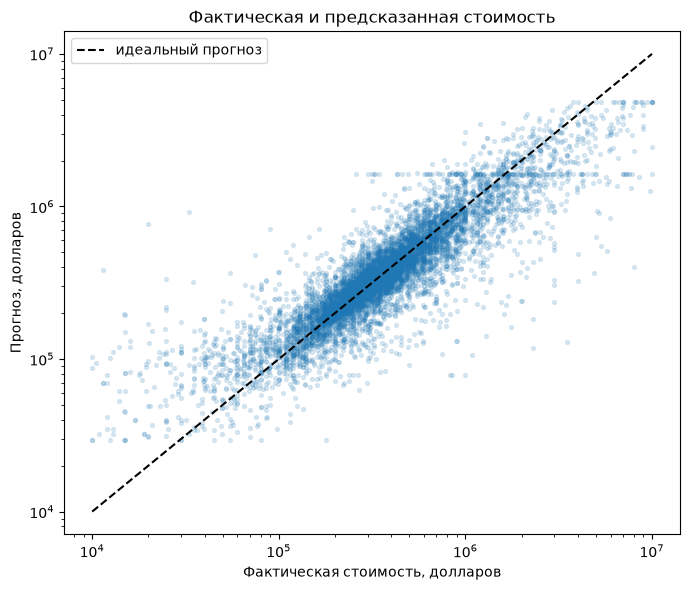

In [13]:
plot_frame = pd.DataFrame({"actual": y_test, "predicted": hist_predictions}).sample(
    n=min(8_000, len(y_test)), random_state=RANDOM_STATE
)
lower = min(plot_frame.min())
upper = max(plot_frame.max())

plt.figure(figsize=(7, 6))
plt.scatter(plot_frame["actual"], plot_frame["predicted"], alpha=0.15, s=8)
plt.plot([lower, upper], [lower, upper], "--", color="black", label="идеальный прогноз")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Фактическая стоимость, долларов")
plt.ylabel("Прогноз, долларов")
plt.title("Фактическая и предсказанная стоимость")
plt.legend()
plt.tight_layout()
plt.show()

## Итоговые выводы

1. Все три ML-модели превосходят медианный baseline, следовательно, признаки
   содержат полезную информацию о цене.
2. Линейный Ridge служит понятной отправной точкой, но хуже учитывает сложные
   взаимодействия площади, местоположения и характеристик дома.
3. Random Forest и HistGradientBoosting моделируют нелинейные зависимости.
4. Подбор гиперпараметров выполнен с групповой кросс-валидацией только на train.
   Настроенная конфигурация не улучшила результат на test, что также является
   полезным результатом эксперимента.
5. Базовый HistGradientBoosting с лучшей итоговой метрикой сохранён в
   `models/final_model.joblib` и используется Streamlit-приложением. Прогноз
   является ориентировочным, особенно для редких и дорогих объектов.